# 12. Работа с трендом и сезонностью

Рабочий ноутбук к главе книги `../chapters/12-trend-seasonality.md`: здесь только задания и код, теория и выводы — в главе. Источник — глава 16 пособия.

Все задания — на синтетике: в реальных рядах магазинов заметного тренда нет.

Графики для главы сохраняй через `save_fig(fig, "имя")` → `../chapters/img/12-имя.png`.

In [1]:
import os
import warnings
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Глушим шум до импорта ETNA: FutureWarning из pandas и предупреждение tqdm про ipywidgets
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

from ruptures import Binseg

from etna.datasets import TSDataset
from etna.transforms import (
    LinearTrendTransform,
    TheilSenTrendTransform,
    ChangePointsTrendTransform,
    STLTransform,
    FourierTransform,
)
from etna.transforms.decomposition.change_points_based.change_points_models import RupturesChangePointsModel
from etna.models import SeasonalMovingAverageModel
from etna.pipeline import Pipeline
from etna.metrics import SMAPE
from etna.analysis import plot_trend, seasonal_plot, stl_plot, acf_plot, plot_periodogram, plot_forecast

IMG_DIR = "../chapters/img"  # графики для главы книги
HORIZON = 14
RANDOM_SEED = 42


def save_fig(fig, name: str) -> None:
    """Сохранить график для главы книги: ../chapters/img/12-<name>.png."""
    os.makedirs(IMG_DIR, exist_ok=True)
    fig.savefig(f"{IMG_DIR}/12-{name}.png", dpi=150, bbox_inches="tight")

## Задание 1. Тренд

Два синтетических ряда, у которых мы знаем настоящий тренд: найти его разными трансформами.

### Шаг 1.1. Два ряда

Одинаковый недельный узор и шум; у первого ряда прямой тренд и 4 сильных выброса, у второго — тренд с изломом.

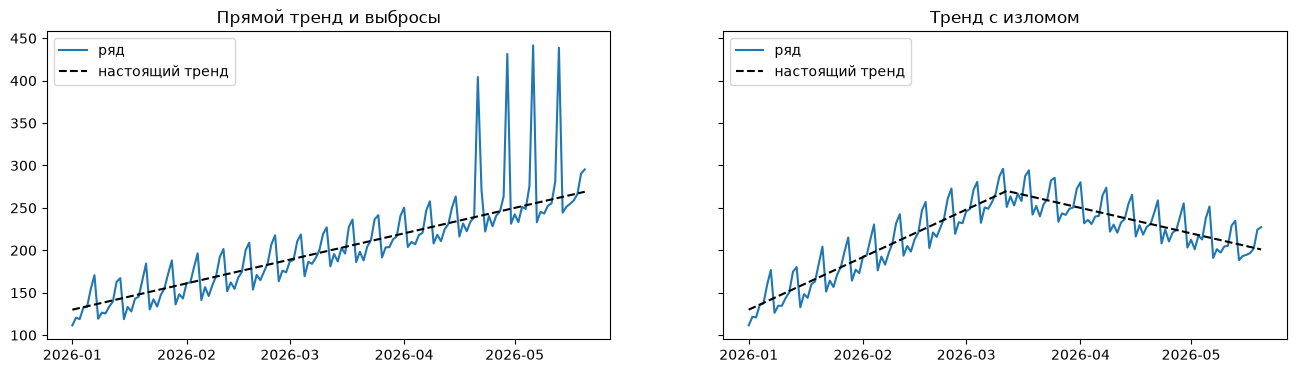

In [2]:
# Два ряда с одинаковым недельным узором и шумом, но разным трендом:
#   «прямой» — тренд +1 в день и 4 сильных выброса во второй половине;
#   «излом»  — тренд растёт на +2 в день до 70-го дня, потом падает на −1 в день
DAY_OF_WEEK_PATTERN = np.array([10, 20, 15, 25, 30, 50, 60], dtype=float)
PERIODS = 20 * 7
t = np.arange(PERIODS)
timestamps = pd.date_range("2026-01-01", periods=PERIODS, freq="D")

TRENDS = {
    "straight": 100 + 1.0 * t,
    "break": np.where(t < 70, 100 + 2 * t, 240 - 1 * (t - 70)),
}
OUTLIERS = {"straight": {110: 150, 118: 150, 125: 150, 132: 150}, "break": {}}


def make_series(name: str) -> TSDataset:
    rng = np.random.RandomState(RANDOM_SEED)
    values = TRENDS[name] + np.tile(DAY_OF_WEEK_PATTERN, PERIODS // 7) + rng.normal(0, 3, PERIODS)
    for day, shift in OUTLIERS[name].items():
        values[day] += shift
    return TSDataset(pd.DataFrame({"timestamp": timestamps, "segment": name, "target": values}), freq="D")


series = {name: make_series(name) for name in TRENDS}
# «Настоящий» тренд для сравнения: к тренду прибавляем среднее недельного узора — оценки тренда включают и его
true_trend = {name: pd.Series(trend + DAY_OF_WEEK_PATTERN.mean(), index=timestamps) for name, trend in TRENDS.items()}

fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharey=True)
for ax, (name, ts) in zip(axes, series.items()):
    ax.plot(timestamps, ts[:, name, "target"].values, color="C0", label="ряд")
    ax.plot(timestamps, true_trend[name].values, color="black", linestyle="--", label="настоящий тренд")
    ax.set_title({"straight": "Прямой тренд и выбросы", "break": "Тренд с изломом"}[name])
    ax.legend(loc="upper left")
save_fig(fig, "series")

#### Выводы

- Оба ряда — 20 недель, недельный узор (самый сильный день на 50 больше самого слабого) и шум ±3.
- **Прямой тренд:** +1 в день, во второй половине 4 выброса на +150.
- **Излом:** до 70-го дня ряд растёт на +2 в день, потом падает на −1 в день. Выбросов нет.

### Шаг 1.2. Прямой тренд и выбросы

`LinearTrendTransform` и `TheilSenTrendTransform`: насколько найденный тренд отличается от настоящего (`trend_mae`) и какой у него наклон в конце ряда (`end_slope`).

настоящий наклон: +1.0 в день


,trend_mae,end_slope
transform,,
LinearTrendTransform,6.28,1.16
TheilSenTrendTransform,4.33,1.01


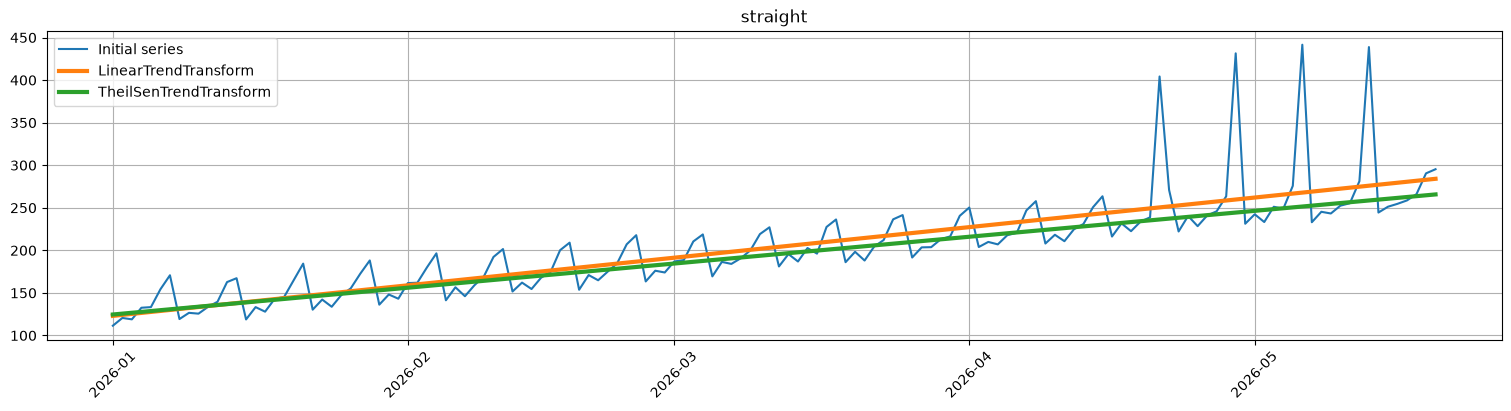

In [3]:
def trend_errors(name: str, transforms: dict) -> pd.DataFrame:
    """Насколько оценённый тренд отличается от настоящего и с каким наклоном он заканчивается."""
    ts = series[name]
    values = ts[:, name, "target"]
    rows = []
    for label, transform in transforms.items():
        ts_detrended = deepcopy(ts)
        ts_detrended.fit_transform([transform])
        fitted_trend = values - ts_detrended[:, name, "target"]  # трансформ вычитает тренд — разница и есть тренд
        rows.append({
            "transform": label,
            "trend_mae": (fitted_trend - true_trend[name]).abs().mean(),
            "end_slope": fitted_trend.diff().iloc[-1],  # наклон в конце ряда — с ним тренд уйдёт в прогноз
        })
    return pd.DataFrame(rows).set_index("transform")


straight_transforms = {
    "LinearTrendTransform": LinearTrendTransform(in_column="target"),
    "TheilSenTrendTransform": TheilSenTrendTransform(in_column="target"),
}
plot_trend(series["straight"], trend_transform=list(straight_transforms.values()), figsize=(15, 4))
save_fig(plt.gcf(), "trend-straight")

print("настоящий наклон: +1.0 в день")
trend_errors("straight", {
    "LinearTrendTransform": LinearTrendTransform(in_column="target"),
    "TheilSenTrendTransform": TheilSenTrendTransform(in_column="target"),
}).round(2)

#### Выводы

| трансформ | ошибка тренда | наклон в конце (настоящий +1) |
|---|---|---|
| `LinearTrendTransform` | 6.3 | 1.16 |
| `TheilSenTrendTransform` | **4.3** | **1.01** |

- **Выбросы тянут обычную регрессию вверх:** 4 точки в конце ряда задрали наклон `LinearTrendTransform` на 16%.
- **Тейл–Сен их почти не замечает:** он берёт медиану наклонов между парами точек, и наклон получился ровно настоящий.

### Шаг 1.3. Тренд с изломом

Те же трансформы и `ChangePointsTrendTransform`: с параметрами по умолчанию и с одним изломом, который ищется по прямым отрезкам.

настоящий наклон в конце: −1.0 в день


,trend_mae,end_slope
transform,,
LinearTrendTransform,26.25,0.54
TheilSenTrendTransform,34.11,0.35
ChangePointsTrendTransform,5.53,-0.22
ChangePointsTrendTransform (1 излом),2.65,-0.85


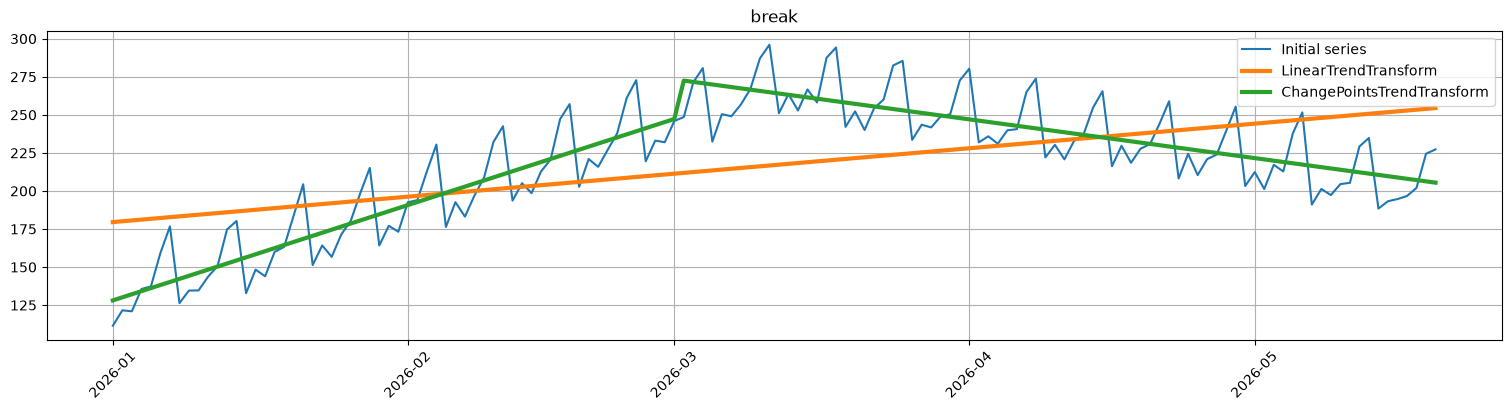

In [4]:
def make_break_transforms() -> dict:
    """Способы найти тренд с изломом. ChangePointsTrendTransform по умолчанию ищет 5 изломов;
    второй вариант знает, что излом один, и ищет его по прямым отрезкам (model="linear")."""
    return {
        "LinearTrendTransform": LinearTrendTransform(in_column="target"),
        "TheilSenTrendTransform": TheilSenTrendTransform(in_column="target"),
        "ChangePointsTrendTransform": ChangePointsTrendTransform(in_column="target"),
        "ChangePointsTrendTransform (1 излом)": ChangePointsTrendTransform(
            in_column="target",
            change_points_model=RupturesChangePointsModel(change_points_model=Binseg(model="linear"), n_bkps=1),
        ),
    }


break_transforms = make_break_transforms()
plot_trend(
    series["break"],
    trend_transform=[break_transforms["LinearTrendTransform"], break_transforms["ChangePointsTrendTransform (1 излом)"]],
    figsize=(15, 4),
)
save_fig(plt.gcf(), "trend-break")

print("настоящий наклон в конце: −1.0 в день")
trend_errors("break", make_break_transforms()).round(2)

#### Выводы

| трансформ | ошибка тренда | наклон в конце (настоящий −1) |
|---|---|---|
| `LinearTrendTransform` | 26.3 | +0.54 |
| `TheilSenTrendTransform` | 34.1 | +0.35 |
| `ChangePointsTrendTransform` по умолчанию | 5.5 | −0.22 |
| `ChangePointsTrendTransform`, 1 излом | **2.7** | **−0.85** |

- **Одна прямая на излом не ложится:** `LinearTrendTransform` и `TheilSenTrendTransform` дают рост, хотя ряд уже 10 недель падает. Такой тренд в прогнозе уведёт его вверх.
- **`ChangePointsTrendTransform` по умолчанию** ищет 5 изломов: тренд в целом похож, но последний кусок короткий и почти плоский (−0.22).
- **Если сказать, что излом один**, наклон в конце почти настоящий (−0.85). Излом найден на 9 дней раньше настоящего — на стыке виден скачок.

## Задание 2. Сезонность

Как увидеть, какие периоды есть в ряде, и разложить его на части. Ряд — с изломом.

### Шаг 2.1. Какие периоды есть в ряде

`acf_plot`, `plot_periodogram`, `seasonal_plot(cycle="week")`.

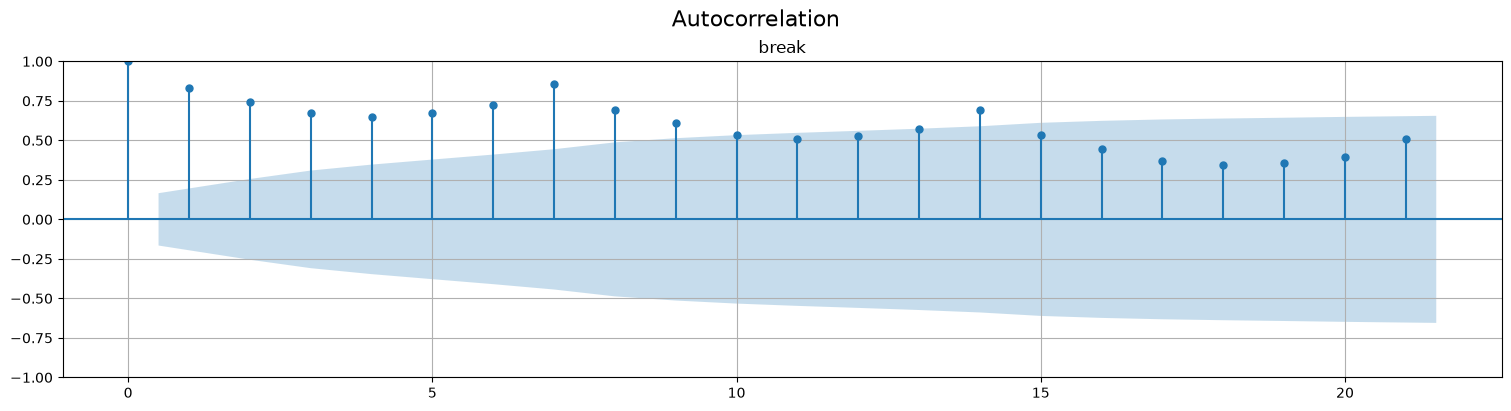

In [5]:
# Сезонность: корреляция ряда с самим собой со сдвигом (ACF) и периодограмма — какие периоды есть в ряде
from unittest.mock import patch

ts = series["break"]
with patch.object(plt, "show"):  # acf_plot сам вызывает plt.show() — без подмены фигура уйдёт раньше, чем её сохраним
    acf_plot(ts, lags=21, figsize=(15, 4))
save_fig(plt.gcf(), "acf")

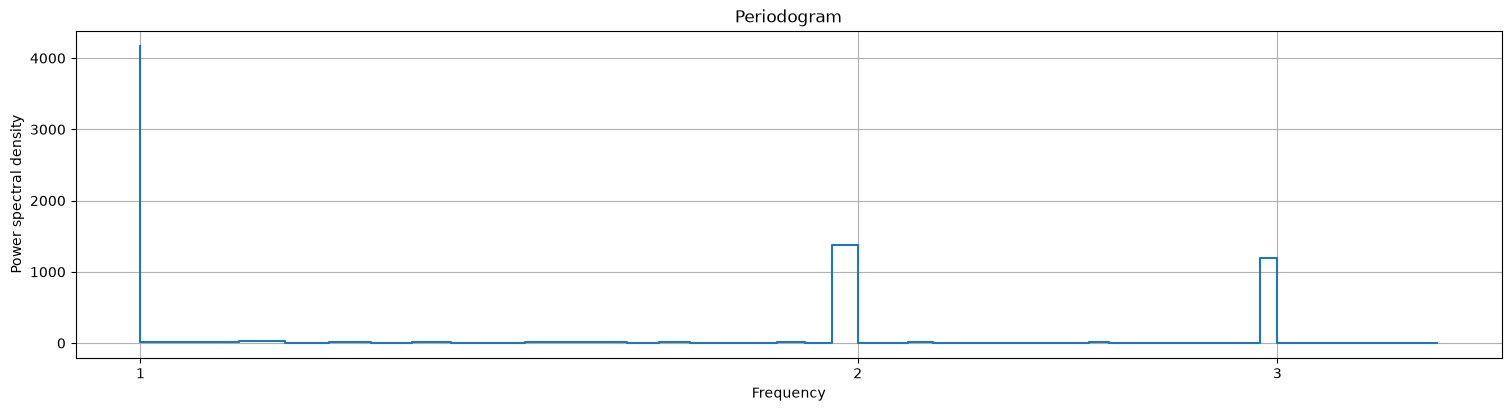

In [6]:
# Периодограмма: «сила» каждой частоты. period=7 — частоты в пересчёте на неделю: 1 — раз в неделю, 2 — дважды
plot_periodogram(ts, period=7, xticks=[1, 2, 3], figsize=(15, 4))
save_fig(plt.gcf(), "periodogram")

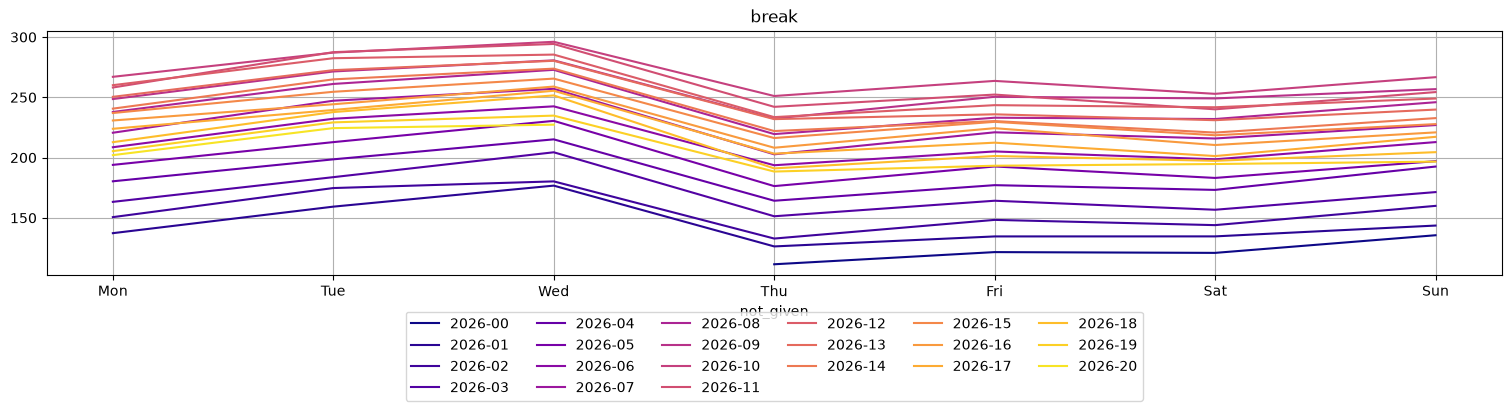

In [7]:
# Недельный профиль: каждая неделя — отдельная линия
seasonal_plot(ts, cycle="week", figsize=(15, 4))
save_fig(plt.gcf(), "seasonal-plot")

#### Выводы

- **ACF:** пики на лагах 7, 14 и 21 — значение похоже на то, что было неделю назад. Все столбики высокие и медленно убывают из-за тренда.
- **Периодограмма:** самый высокий пик на частоте 1 раз в неделю, пики поменьше на 2 и 3 — так узор недели, не похожий на синусоиду, раскладывается на гармоники.
- **`seasonal_plot`:** каждая неделя — своя линия; форма у всех одна (среда — пик, четверг — провал), а уровень сдвигается вместе с трендом.

### Шаг 2.2. Разложение STL

`stl_plot(period=7)`: тренд, сезонность и остаток.

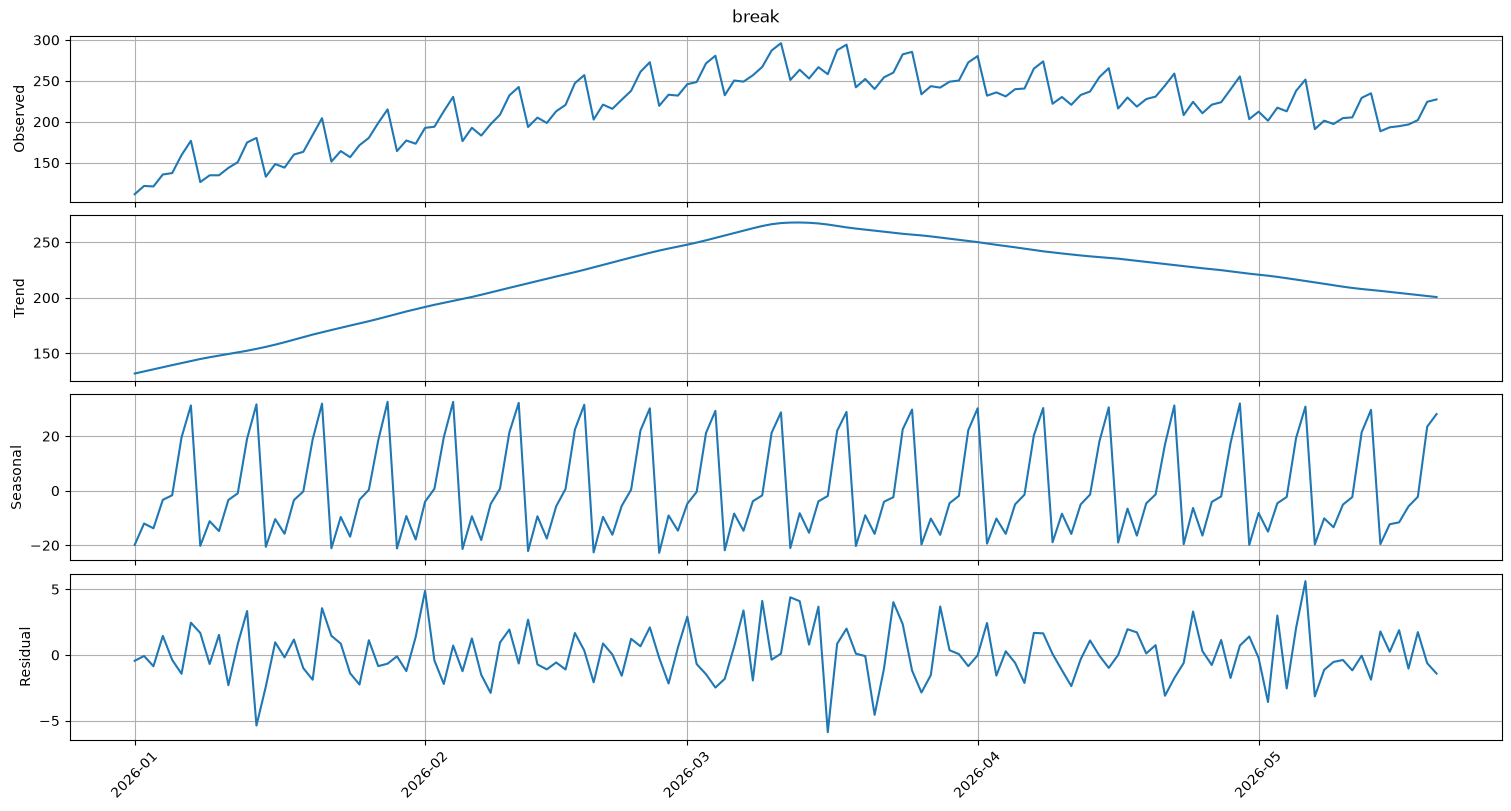

In [8]:
# STL раскладывает ряд на тренд, сезонность и остаток
stl_plot(ts, period=7, figsize=(15, 8))
save_fig(plt.gcf(), "stl")

#### Выводы

- **Тренд STL** повторяет излом, но скругляет его: это сглаживание, а не прямые отрезки.
- **Сезонность** — тот же недельный узор, размах около 50, как и задавали.
- **Остаток** — шум ±5, без структуры: тренд и сезонность забрали всё.

## Задание 3. Трансформы в конвейере

Помогают ли трансформы тренда и сезонности прогнозу и что получает ML-модель.

### Шаг 3.1. Прогноз ряда с изломом

`SeasonalMovingAverageModel(window=4, seasonality=7)` сама тренд не видит. Прогноз на 14 дней без трансформов и с `LinearTrendTransform`, `ChangePointsTrendTransform` (1 излом), `STLTransform(period=7)`.

,smape
без трансформов,9.86
+ LinearTrendTransform,16.54
+ ChangePointsTrendTransform (1 излом),3.06
+ STLTransform,5.19


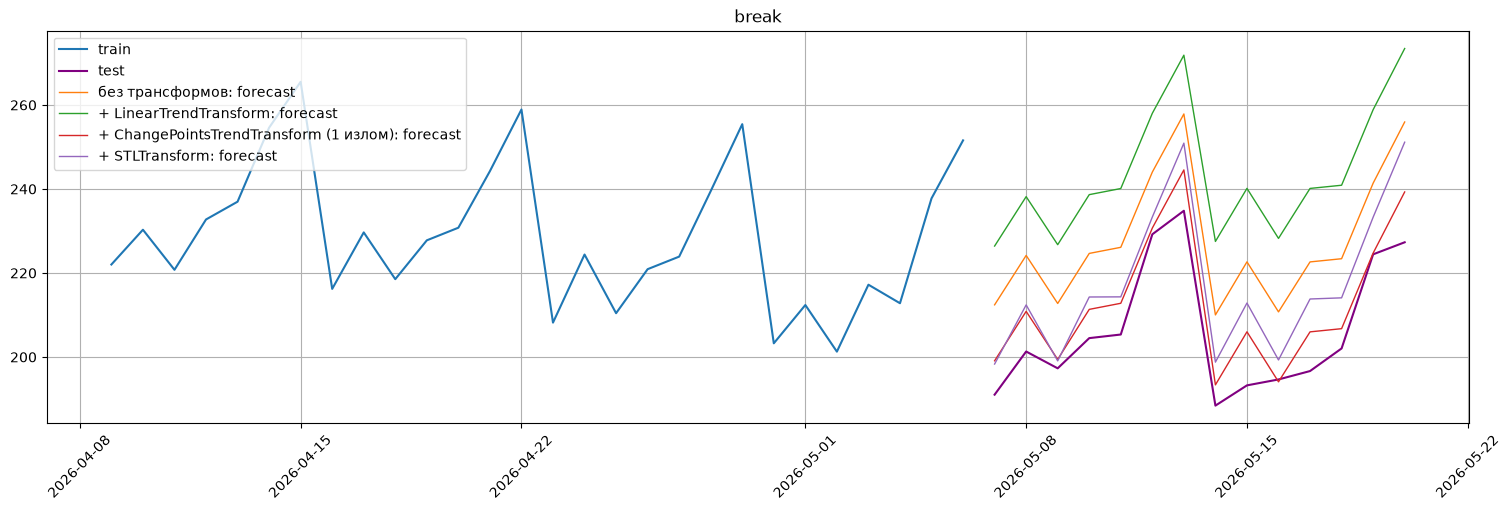

In [9]:
# Прогноз на 14 дней для ряда с изломом: модель без тренда (сезонное скользящее среднее) — с трансформами и без
train_ts, test_ts = series["break"].train_test_split(test_size=HORIZON)


def make_pipelines() -> dict:
    model = lambda: SeasonalMovingAverageModel(window=4, seasonality=7)
    return {
        "без трансформов": Pipeline(model(), transforms=[], horizon=HORIZON),
        "+ LinearTrendTransform": Pipeline(model(), transforms=[LinearTrendTransform(in_column="target")], horizon=HORIZON),
        "+ ChangePointsTrendTransform (1 излом)": Pipeline(
            model(),
            transforms=[make_break_transforms()["ChangePointsTrendTransform (1 излом)"]],
            horizon=HORIZON,
        ),
        "+ STLTransform": Pipeline(model(), transforms=[STLTransform(in_column="target", period=7)], horizon=HORIZON),
    }


forecasts = {}
for name, pipeline in make_pipelines().items():
    pipeline.fit(train_ts)
    forecasts[name] = pipeline.forecast()

plot_forecast(forecast_ts=forecasts, test_ts=test_ts, train_ts=train_ts, n_train_samples=28, figsize=(15, 5))
save_fig(plt.gcf(), "forecasts")

pd.DataFrame({"smape": {name: SMAPE()(y_true=test_ts, y_pred=forecast)["break"] for name, forecast in forecasts.items()}}).round(2)

#### Выводы

| конвейер | SMAPE, % |
|---|---|
| без трансформов | 9.9 |
| + `LinearTrendTransform` | 16.5 |
| + `ChangePointsTrendTransform` (1 излом) | **3.1** |
| + `STLTransform` | 5.2 |

- **Без трансформов** модель берёт среднее за 4 прошлые недели — а ряд падает, поэтому прогноз выше факта.
- **Неправильный тренд хуже, чем никакого:** `LinearTrendTransform` нашёл рост и задрал прогноз ещё выше.
- **Правильный тренд снижает ошибку втрое:** `ChangePointsTrendTransform` с одним изломом. `STLTransform` без настройки тоже помог вдвое.

### Шаг 3.2. Признаки Фурье

`FourierTransform(period=7, order=2)`: какие колонки он добавляет.

In [10]:
# Признаки сезонности для ML-моделей: синусы и косинусы с периодом 7 дней
ts_fourier = deepcopy(series["break"])
ts_fourier.fit_transform([FourierTransform(period=7, order=2, out_column="fourier")])
fourier_df = ts_fourier.to_pandas(flatten=True).set_index("timestamp").drop(columns=["segment", "target"])
fourier_df["day_of_week"] = fourier_df.index.day_name()
fourier_df.head(8).round(2)

,fourier_1,fourier_2,fourier_3,fourier_4,day_of_week
timestamp,,,,,
2026-01-01,0.00,1.00,0.00,1.00,Thursday
2026-01-02,0.78,0.62,0.97,-0.22,Friday
2026-01-03,0.97,-0.22,-0.43,-0.90,Saturday
2026-01-04,0.43,-0.90,-0.78,0.62,Sunday
2026-01-05,-0.43,-0.90,0.78,0.62,Monday
2026-01-06,-0.97,-0.22,0.43,-0.90,Tuesday
2026-01-07,-0.78,0.62,-0.97,-0.22,Wednesday
2026-01-08,-0.00,1.00,-0.00,1.00,Thursday


#### Выводы

- **4 колонки на `order=2`:** синус и косинус с периодом 7 дней (`fourier_1`, `fourier_2`) и с периодом 3.5 дня (`fourier_3`, `fourier_4`).
- **Каждый день недели получает свою точку на круге:** значения повторяются ровно через 7 дней (два четверга в таблице совпадают).
- Это признаки для ML-моделей (например, CatBoost): сами по себе ряд они не меняют, поэтому трансформ необратимый.